# Is the unchanged decomposition already poor at the cipher's cue? (E48)

## The answer

Yes. We rebuilt the unchanged model from the subcomponents its causal-importance function marks important. At the cue of the word ciphers, that model is about twice as far from the original as it is on ordinary text, over the agreed line on both random ciphers. So the planned new part of the pass would have judged the decomposition, not the map. The pass for new behaviours stays the adversarial check on ordinary text, with the cue reading printed beside it.

## What we were trying to test

E42 found that teacher training copies a word-cipher fine-tune into the decomposition and passes the adversarial check on ordinary text. Yet the model rebuilt from the subcomponents Γ marks important at the cipher's cue keeps almost none of a random cipher. On 2026-10-29 the user chose to add a new part to the pass: the behaviour must also be kept by the parts Γ switches on, on the task's own text. The same decision said to check the unchanged decomposition first. If its own masked model is already poor at the cipher's cue, the new reading would fail every map for a reason that lies in the decomposition, and the pass falls back to the ordinary-text check.

This run made only that first check. The state is W₀, the unchanged model with its decomposition. Its **masked model** is the forward pass with every subcomponent multiplied by Γ's causal-importance value $g$, with Γ reading W₀'s own activations. Δ, the part of the weights outside the subcomponents, is held at W₀'s value. Three quantities:

- **The KL at the cue**: the mean over a task's held-out windows of $\mathrm{KL}(W_0 \,\|\, \text{masked } W_0)$ at the one position after the cipher's marker and key, in nats. 0 means the masked model reproduces W₀ there exactly.
- **The KL on ordinary text**: the same, per position, averaged over 256 rows of Pile validation text.
- **The ratio $F$** of the two. $F = 1$ means the masked model is as close to W₀ at the cue as on ordinary text.

The stop rule reads $F$ on the two random ciphers, one with 32 key-to-word pairs and one with a single pair. At 1.5 or over on either, the new reading is not used. Printed beside, and not scored, are two kinds of reference. One is the identity control, where each of the same 32 keys maps to itself. The others are the cue windows of four earlier tasks that VPD is not suspected of losing: emoticon → o, the first two rungs of the task ladder, and the rare target " in" → " Fig". Two apparatus checks came first: the masked forward reproduces the harness's ordinary-text reading, and W₀'s Δ really enters it.

## What we expected, and why

We leaned towards the fallback, with medium-low confidence. With Δ left out, earlier numbers put the masked model 0.69 nats from W₀ at the cipher's cue, against 0.35 on ordinary text, a ratio of about 2. Putting W₀'s Δ back in could have lowered either number by an amount nobody had measured, so the lean was not firm.

## What we observed

### Is the unchanged decomposition's masked model already poor at the cipher's cue? Yes, on both random ciphers

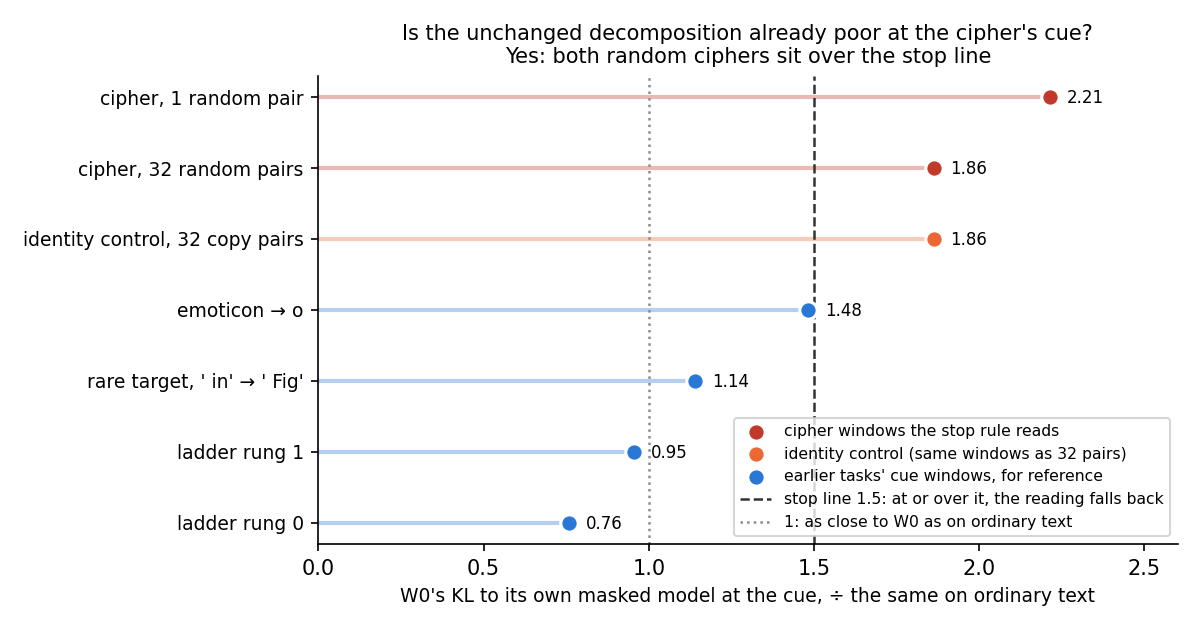

In [1]:
# The figure, made by experiments/pass_reread/plot.py from results/saved.json (no model).
from IPython.display import Image

Image("../experiments/pass_reread/figures/e48_s1_fidelity.png")

**Reading it.** Yes. At the cue of the 32-pair cipher the masked model is 0.65 nats from W₀, 1.86 times its distance on ordinary text. On the one-pair cipher it is 0.77 nats, 2.21 times. Both dots sit right of the dashed stop line at 1.5, so the run stopped after this check, as planned. The four earlier tasks' cues read 0.76 to 1.48, all under the line, with emoticon closest to it. So the cipher's cue context is harder for the decomposition than the cues of the tasks it handles, and harder than the line allows.

The identity control reads exactly what the 32-pair cipher reads. That is expected: both tasks use the same windows, drawn once for the same 32 keys, and only the word each key maps to differs. This reading compares W₀ with its own masked model, so it never looks at the target word. The one-pair cipher has its own windows and reads differently. Putting W₀'s Δ into the masked forward changed every reading by under 0.004 nats, so the choice of Δ convention did not matter here.

In [2]:
# The numbers behind the figure, from the results file (no model).
import json
from pathlib import Path

s1 = json.loads(Path("../experiments/pass_reread/results/saved.json").read_text())["S1"]
names = {"rand1": "cipher, 1 pair", "rand32": "cipher, 32 pairs", "ident32": "identity, 32 pairs",
         "emoticon": "emoticon", "r2_t275_v2667": "rare target", "r1_t534_v369": "ladder rung 1",
         "r0_t352_v310": "ladder rung 0"}
print(f"{'cue windows':20s} {'KL at cue':>10s} {'ratio F':>8s} {'over 1.5':>9s}")
for key, name in names.items():
    print(f"{name:20s} {s1['K0'][key]['K']:10.3f} {s1['F'][key]:8.2f} {str(s1['F'][key] >= 1.5):>9s}")
print(f"{'ordinary text':20s} {s1['pile']['K']:10.3f} {1:8.2f}")
print("decision:", s1["decision"])

cue windows           KL at cue  ratio F  over 1.5
cipher, 1 pair            0.771     2.21      True
cipher, 32 pairs          0.648     1.86      True
identity, 32 pairs        0.648     1.86      True
emoticon                  0.516     1.48     False
rare target               0.397     1.14     False
ladder rung 1             0.332     0.95     False
ladder rung 0             0.264     0.76     False
ordinary text             0.348     1.00
decision: fallback


## What we learned

Before any update, the unchanged decomposition is about twice as far from W₀ at the cipher's cue as on ordinary text. The cue follows a marker the model never sees in ordinary text, a context the decomposition was not trained on. A reading of behaviour kept by the parts Γ switches on at that cue would measure the decomposition's own gap as much as the map's. For the weak version in `GOALS.md`, the pass on new behaviours therefore stays the adversarial check on ordinary text, and the cue reading is printed beside each verdict without deciding it. E42's result stands as filed: teacher training passes on all three ciphers, while the model rebuilt from the subcomponents Γ marks important at the cue keeps almost none of a random cipher.

Two cards follow. The E42 criterion is decided as the fallback the user named: the ordinary-text check decides, with the cue reading beside it. The rare target was to be re-read under the new reading; since that reading is not used, its outcome under the ordinary-text check stands, "not placed, narrow miss", with no rerun.

## How compelling is the evidence

Each cipher reading is a mean over 97 held-out windows, on one decomposition and one card. The reading has no randomness: Γ's values and the masked forward are deterministic, so a rerun on the same card reads the same. Both ciphers clear the line, by 0.36 and 0.71. The line is the project's fixed 1.5, applied here to W₀ against itself and filed before the run; the verdict rests on that choice. Any line from 1.49 to 2.21 would keep every earlier task under it and still give the fallback. The reading compares one cue position with the mean over every ordinary-text position. The earlier tasks' cues are the same kind of position and read lower, so the cipher's excess is not only the position type. In absolute terms the gap is small beside the 10 to 13 nats that E42's fine-tunes move the cue. But a share measured against a reference twice as poor as usual would not have read the map alone.

## Surprises

None reversed a prediction: the run landed on its lean. One small surprise: W₀'s Δ adds almost nothing under the masks, under 0.004 nats at any cue, though with every mask at 1 leaving it out costs 0.011 nats per ordinary-text position.

## What next

1. Nothing runs on this line by default. Under the fallback, the E42 copies' cue readings are already in E42's write-up. The E34 copies' cue readings are printed nowhere yet; a free, ten-minute rerun of the copy-reading stage, reported beside and deciding nothing, would print them if wanted.
2. If a later decomposition or a masked training brings W₀ under 1.5 at the cipher's cue, the new reading becomes usable, and this run's code reads every saved copy unchanged. The Qwen line's plan uses the same share; its own W₀ should be read the same way at its task's cue first.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| S1 A1 | masked forward is the harness's | Δ-out Pile KL within 2% of 0.348 | 0.3482 | pass |
| S1 A2 | Δ enters the masked forward | fp32 KL at mask 1 ≤ 1e-4 | −1.3e-9 | pass |
| S1 | W₀ already poor at the cue; lean fallback | F ≥ 1.5 on rand32 or rand1 | 1.86, 2.21 | **fallback**, as leaned |
| P1-P5 | copies and controls under the new reading | share ≥ 0.8 | not read | not scored: stopped by design |
| P6 | batch-order spread under 0.05 | max share difference | not read | not scored |
| P7 | carriers of the E42 gain: tens | n50 count | not read | not scored |

## Not run

- The saved copies under the new reading: E42's six, the r1 and r2 SGD copies including the rare target's, the six LoRA copies, and the do-nothing states. Stopped by design.
- The subcomponents that carry the E42 gain. Stopped by design.
- The second job, E34's six copies regenerated on the L40. Not submitted, by the plan.
- The "reported beside" rerun of the copies' cue readings. Not asked for.

## Provenance

Slurm job 42757, MATS cluster debug QoS, NVIDIA L40, about 2 minutes, exit 0, $0. Results `experiments/pass_reread/results/saved.json`; predictions `experiments/pass_reread/results/predictions.json`, filed before the run; plan `reports/plans/2026-10-29_plan_e48-pass-reread.md`; full tables in `reports/analyses/2026-10-29_analysis_e48-pass-reread.md`.

# Amendment 1: how many subcomponents carry the copies' gain at the cipher's cue?

We took the three teacher-trained decompositions from the earlier cipher experiment and, one subcomponent at a time, undid that subcomponent's training to see how much of the cipher's gain at its cue went with it. On every copy, one to two thousand subcomponents carry half of the gain, far more than the tens we filed, and the copy of a cipher the model already half did spreads about as widely as the new ones. So the repair is not a small change to which subcomponents the importance function switches on, and this count does not tell a new behaviour from an old one.

## The answer

Hundreds, not tens. On each of the three copies, between about one and two thousand of the 9,881 alive subcomponents are needed to carry half of the gain at the cipher's cue. We filed "tens" for both random ciphers, so that prediction missed on both. The identity control, a cipher the model already half did, spreads about as widely. So the count does not separate a new behaviour from an existing one, and it rules out a repair that switches on a few subcomponents.

Why it ran: the first stage above fell back, which stopped its job before this listing. The task still asked for it, and the listing describes where the gain sits rather than whether a copy passes, so the fallback does not bear on it. It ran alone, with the filed prediction unchanged.

## What we were trying to test

E42 made three copies by teacher training, one per cipher task. Teacher training trains the alive subcomponents' read and write vectors, starting from the unchanged decomposition, so that the decomposition's model imitates a fine-tune; Γ and Δ stay fixed. The tasks:

- **32 random pairs**: each of 32 keys maps to an arbitrary other word. A behaviour the model lacked.
- **1 random pair**: one key and its value. Also new.
- **Identity control**: each of the same 32 keys is followed by itself. The model half did this already; in E10 the fine-tune's gain on it came from Γ switching on subcomponents that already copy.

The **gain** of a copy is its mean log-odds of the target at the cue, minus the unchanged model's, over the task's 97 held-out windows. The cue is the position right after the marker and the key. The gains read about 21, 23 and 19 nats, matching E42's own readings.

For each alive subcomponent we set its read and write vectors back to their unchanged values, kept every other subcomponent as the copy had it, and read the gain again. The **drop** is how much the gain fell; 0 means that subcomponent's training does nothing at the cue. From the drops, sorted largest first:

- **n50**: the fewest subcomponents whose drops reach half of the summed positive drops; **n90**, nine tenths.
- **The off share**: the part of the n50 set's summed drop that comes from subcomponents Γ keeps off at the cue, its value under 0.01.
- **The joint revert**: the whole n50 set set back at once, as a fraction of the gain. It checks whether the separate drops roughly add.

The filed rule calls n50 "a handful" at 10 or fewer and "hundreds" at 100 or more, with "tens" between. "A handful" would point to a small change to Γ as the repair; "hundreds" would not.

## What we expected, and why

We filed "tens" for both random ciphers, with low confidence and no reference. Teacher training moves every alive subcomponent, which argues for a wide spread, but a one-pair cipher should need few directions. No lean was filed for the identity control; it is the contrast.

## What we observed

### How many subcomponents carry half of the gain? About a thousand or more, on all three copies

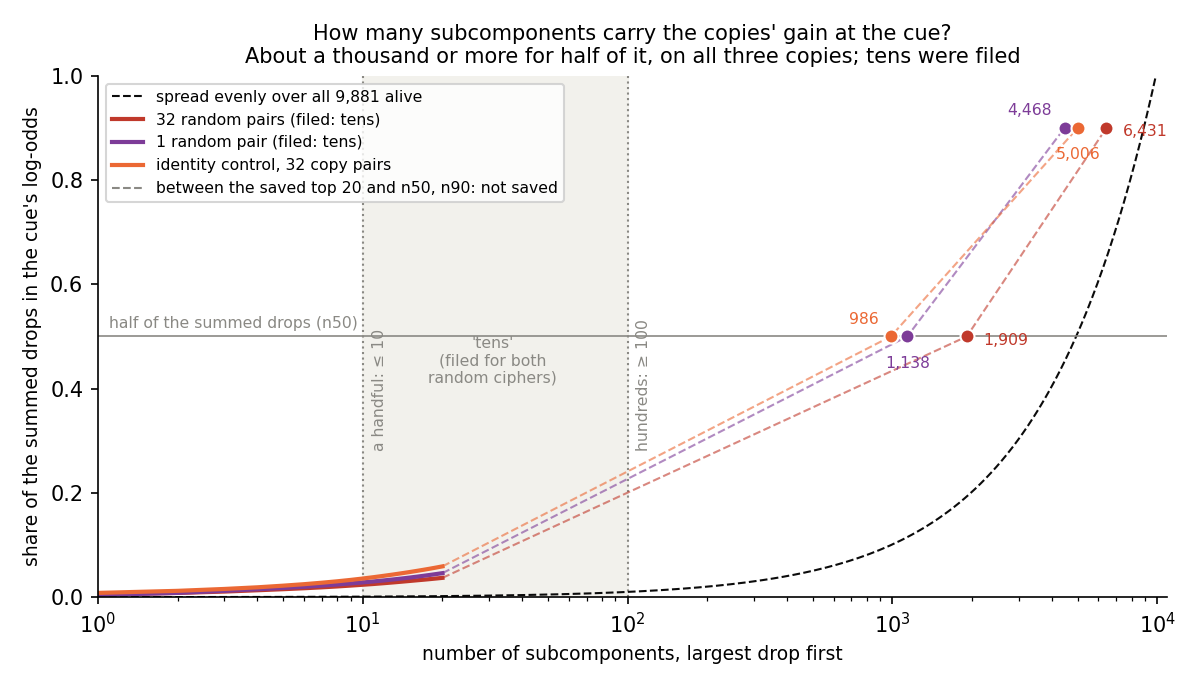

In [3]:
# The figure, made by experiments/pass_reread/plot_amend1.py from results/carriers.json (no model).
Image("../experiments/pass_reread/figures/e48_a1_carriers.png")

**Reading it.** Hundreds on all three, and the filed "tens" missed on both random ciphers. The figure plots, for each copy, the share of the summed drops carried by the largest drops against how many are counted. Only the top 20 drops and n50, n90 were saved, so the curves are exact there and dashed between. The 20 largest drops carry under 6% of the total, against 0.2% if the drops were spread evenly. Half of it needs 1,909 subcomponents on 32 random pairs and 1,138 on one pair. So the gain is concentrated well beyond an even spread, but nowhere near a handful.

The identity control needs 986 for half and 5,006 for nine tenths, inside the range the two random ciphers span. On this measure, a copy of a behaviour the model already half did spreads over as many subcomponents as a copy of a new one. The off share does not split them either: it reads 0.64 on one pair, but 0.42 on 32 pairs and 0.39 on the identity control. Setting the n50 set back together removes 58 to 74% of the gain, about what its drops add to, so about a third of the gain sits in the remaining eight to nine thousand subcomponents.

In [4]:
# The numbers behind the figure, from the results file (no model).
c = json.loads(Path("../experiments/pass_reread/results/carriers.json").read_text())
names = {"e42/rand32/A": "32 random pairs", "e42/rand1/A": "1 random pair", "e42/ident32/A": "identity control"}
print(f"{'copy':18s} {'n50':>6s} {'n90':>6s} {'off share':>10s} {'joint revert':>13s}")
for key, name in names.items():
    r = c["carriers"][key]
    print(f"{name:18s} {r['n50']:6d} {r['n90']:6d} {r['n50_near_zero_share']:10.2f} {r['n50_joint_removed']:13.2f}")
print("alive subcomponents:", c["carriers"]["e42/rand32/A"]["n_alive"])

copy                  n50    n90  off share  joint revert
32 random pairs      1909   6431       0.42          0.66
1 random pair        1138   4468       0.64          0.58
identity control      986   5006       0.39          0.74
alive subcomponents: 9881


## What we learned

A large part of the decomposition carries a teacher-trained copy's gain at the cipher's cue: about a thousand subcomponents or more for half of it. That points away from a repair that keeps the copy and has Γ switch on a few more subcomponents at the cue. On `GOALS.md`'s question of whether a new behaviour spreads more than an existing one, this count gives no sign of it: the identity control spreads as widely as the two new ciphers. What the comparison does not show is whether the wide spread belongs to the behaviours or to teacher training, which moves every alive subcomponent; no copy of a narrowly placed behaviour was read beside them.

## How compelling is the evidence

The counts are far from the filed line: the smallest n50, 986, is almost ten times the "hundreds" line. The reading is deterministic, each drop a mean over 97 held-out windows on one card. It covers one copy per task, one seed and one batch order, on the 67M. The measure undoes one subcomponent at a time, so it is blind to interactions beyond the n50 set's joint revert. It cannot tell a spread the optimiser made from a spread the behaviour needs.

## Surprises

- The filed "tens" missed on both random ciphers by more than a factor of ten. The lean was low, but this is not a narrow miss.
- The identity control spreads about as widely as the new ciphers, where a narrower spread was the natural guess for a behaviour Γ already handles.

## What next

1. Nothing by default: "hundreds" rules out a small Γ change as the repair, and the masked-copy line already ended in E42 Amendment 2.
2. If the spread question matters, the same listing on an E34 copy of a behaviour the model half did, regenerated on the L40 for $0. Well under a hundred there would make the spread a property of these behaviours; about a thousand would make it teacher training's.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P7 | rand32: carriers number tens; lean low | n50 ≤ 10 handful, ≥ 100 hundreds, else tens | 1,909 | **hundreds**: miss |
| P7 | rand1: same | same | 1,138 | **hundreds**: miss |
| beside | ident32, not filed | same | 986 | hundreds |

## Not run

- The full sorted drops: only the top 20, n50 and n90 were saved.
- A reference count from another state: do-nothing, E42's least-squares split, an E34 copy, or the fine-tune.
- E42's Pile-text copies and the E34 copies under the same listing.
- A joint revert of the n90 set, or of sets chosen by Γ's value.
- Any change to Γ itself; a second seed, batch order or card.

## Provenance

Slurm job 42960, MATS cluster debug QoS, NVIDIA L40, about 3 minutes per copy, exit 0, $0. Results `experiments/pass_reread/results/carriers.json`; full table in `reports/analyses/2026-10-29_analysis_e48-pass-reread.md` → "Amendment 1".